In [2]:

print("Proje: Müşteri Yorumu Duygu Analizi\nProblem: Yorum metninden duygu tahmini\nProblem türü: Sınıflandırma\nHedef değişken: labels")

Proje: Müşteri Yorumu Duygu Analizi
Problem: Yorum metninden duygu tahmini
Problem türü: Sınıflandırma
Hedef değişken: labels



# PROJE: Müşteri Yorum Duygu Analizi
AŞAMA 1: Problem Tanımı
Problem:
Bir müşteri yorumunun olumlu veya olumsuz
olduğunu tahmin etmek.

Problem türü: İkili sınıflandırma
Hedef değişken: labels
Özellikler: text, word_count, char_count


# VERİ TOPLAMA VE HAZIRLAMA


In [3]:





import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


df = pd.read_csv("/content/drive/MyDrive/musteri_yorumlari.csv")


print("\nİlk 5 veri:")
display(df.head())
display(df.describe())

print("\nVeri boyutu:", df.shape)


print("\nVeri tipleri:")
print(df.dtypes)


print("\nEksik değerler:")
print(df.isnull().sum())


df = df.dropna(subset=["text", "labels"])


df = df.drop_duplicates(subset=["text"])









İlk 5 veri:


,text,labels,word_count,char_count
0,"The food was absolutely amazing, every bite wa...",positive,11,63
1,"Terrible service, we waited over an hour just ...",negative,12,64
2,"The ambiance was cozy and romantic, perfect fo...",positive,11,61
3,"Overpriced for such small portions, definitely...",negative,9,60
4,The staff was super friendly and attentive thr...,positive,10,63


,word_count,char_count
count,100.000000,100.000000
mean,9.350000,57.540000
std,1.876893,6.871725
min,6.000000,38.000000
25%,8.000000,54.750000
50%,9.000000,58.000000
75%,10.000000,62.000000
max,14.000000,73.000000



Veri boyutu: (100, 4)

Veri tipleri:
text          object
labels        object
word_count     int64
char_count     int64
dtype: object

Eksik değerler:
text          0
labels        0
word_count    0
char_count    0
dtype: int64



# KEŞİFÇİ VERİ ANALİZİ (EDA)


In [4]:

df["word_count"] = df["text"].astype(str).str.split().str.len()
df["char_count"] = df["text"].astype(str).str.len()

print("\nTemizleme sonrası veri boyutu:", df.shape)


data_dictionary = pd.DataFrame({
    "Sütun": ["text", "labels", "word_count", "char_count"],
    "Veri Tipi": ["Metin", "Kategorik", "Sayısal", "Sayısal"],
    "Açıklama": [
        "Müşteri yorumunun kendisi",
        "Yorumun olumlu veya olumsuz olması",
        "Yorumdaki kelime sayısı",
        "Yorumdaki karakter sayısı"
    ]
})

print("\nVeri sözlüğü:")
display(data_dictionary)


Temizleme sonrası veri boyutu: (100, 4)

Veri sözlüğü:


,Sütun,Veri Tipi,Açıklama
0,text,Metin,Müşteri yorumunun kendisi
1,labels,Kategorik,Yorumun olumlu veya olumsuz olması
2,word_count,Sayısal,Yorumdaki kelime sayısı
3,char_count,Sayısal,Yorumdaki karakter sayısı


# Özellikleri yeniden hesaplama


Sayısal özet:


,word_count,char_count
count,100.000000,100.000000
mean,9.350000,57.540000
std,1.876893,6.871725
min,6.000000,38.000000
25%,8.000000,54.750000
50%,9.000000,58.000000
75%,10.000000,62.000000
max,14.000000,73.000000



Sınıf dağılımı:
labels
positive    50
negative    50
Name: count, dtype: int64

Sınıflara göre ortalama değerler:


,word_count,char_count
labels,,
negative,10.06,57.10
positive,8.64,57.98


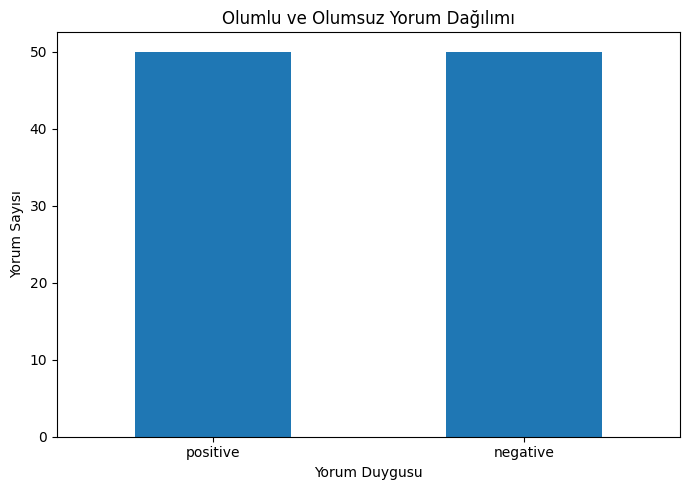

<Figure size 700x500 with 0 Axes>

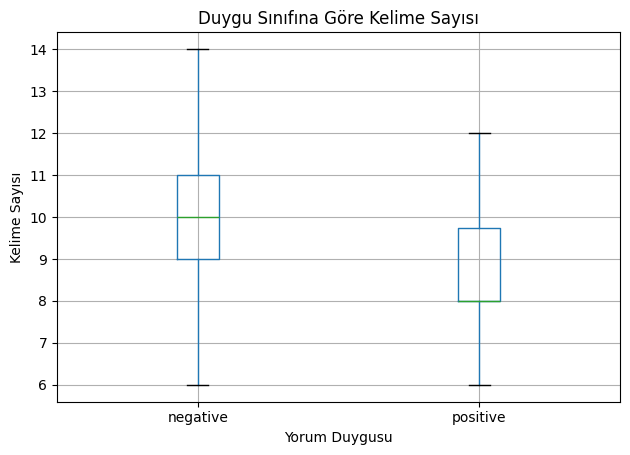

In [5]:

print("\nSayısal özet:")
display(df.describe())


print("\nSınıf dağılımı:")
print(df["labels"].value_counts())


print("\nSınıflara göre ortalama değerler:")
display(
    df.groupby("labels")[["word_count", "char_count"]].mean()
)


plt.figure(figsize=(7, 5))

df["labels"].value_counts().plot(
    kind="bar",
    rot=0
)

plt.title("Olumlu ve Olumsuz Yorum Dağılımı")
plt.xlabel("Yorum Duygusu")
plt.ylabel("Yorum Sayısı")
plt.tight_layout()
plt.show()



plt.figure(figsize=(7, 5))

df.boxplot(
    column="word_count",
    by="labels"
)

plt.title("Duygu Sınıfına Göre Kelime Sayısı")
plt.suptitle("")
plt.xlabel("Yorum Duygusu")
plt.ylabel("Kelime Sayısı")
plt.tight_layout()
plt.show()



 # MODEL KURMA VE EĞİTME


In [6]:



from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier


X = df[["text", "word_count", "char_count"]]
y = df["labels"]


X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,
    random_state=42,
    stratify=y
)


preprocessor = ColumnTransformer(
    transformers=[
        ("text", TfidfVectorizer(), "text"),
        ("numeric", "passthrough", ["word_count", "char_count"])
    ]
)


model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ))
])


model.fit(X_train, y_train)


print("Eğitim verisi:", X_train.shape)
print("Test verisi:", X_test.shape)




Eğitim verisi: (80, 3)
Test verisi: (20, 3)



 TAHMİN VE DEĞERLENDİRME



#  TAHMİN VE DEĞERLENDİRME

--------------------------------
Accuracy : 0.55
Precision : 0.54
Recall : 0.70
F1 Score: 0.61

Detaylı sınıflandırma raporu:
              precision    recall  f1-score   support

    negative       0.57      0.40      0.47        10
    positive       0.54      0.70      0.61        10

    accuracy                           0.55        20
   macro avg       0.55      0.55      0.54        20
weighted avg       0.55      0.55      0.54        20



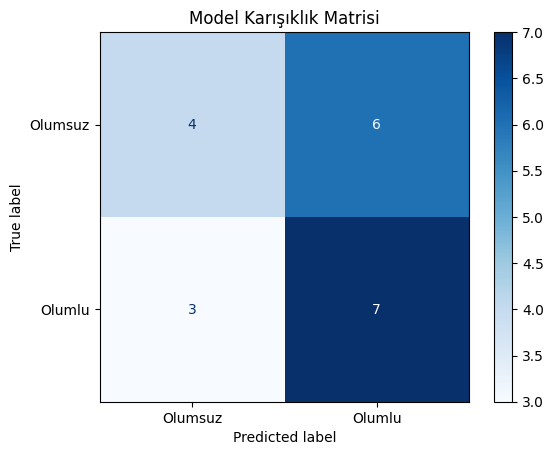

In [7]:


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, pos_label="positive"
)
recall = recall_score(
    y_test, y_pred, pos_label="positive"
)
f1 = f1_score(
    y_test, y_pred, pos_label="positive"
)


print("--------------------------------")
print(f"Accuracy : {accuracy:.2f}")
print(f"Precision : {precision:.2f}")
print(f"Recall : {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

print("\nDetaylı sınıflandırma raporu:")
print(classification_report(y_test, y_pred))


cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["negative", "positive"]
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Olumsuz", "Olumlu"]
)

display_matrix.plot(cmap="Blues")
plt.title("Model Karışıklık Matrisi")
plt.show()





 3 YENİ YORUM İÇİN TAHMİN


In [8]:


new_reviews = [
    "The food was amazing and the staff were very friendly.",
    "The service was terrible and the food was cold.",
    "I enjoyed my visit and would definitely come back."
]

new_data = pd.DataFrame({
    "text": new_reviews,
    "word_count": [len(review.split()) for review in new_reviews],
    "char_count": [len(review) for review in new_reviews]
})

new_predictions = model.predict(new_data)

results = pd.DataFrame({
    "Yorum": new_reviews,
    "Tahmin": new_predictions
})

results["Tahmin"] = results["Tahmin"].map({
    "positive": "Olumlu",
    "negative": "Olumsuz"
})


display(results)


,Yorum,Tahmin
0,The food was amazing and the staff were very f...,Olumsuz
1,The service was terrible and the food was cold.,Olumsuz
2,I enjoyed my visit and would definitely come b...,Olumlu


DecisionTreeClassifier sınıflandırma modelini kullandım

# KULLANICI GİRDİSİ İLE TAHMİN.

In [9]:



def tahmin_et(yorum):

    yeni_veri = pd.DataFrame({
        "text": [yorum],
        "word_count": [len(yorum.split())],
        "char_count": [len(yorum)]
    })


    tahmin = model.predict(yeni_veri)[0]

    if tahmin == "positive":
        return "Olumlu "
    else:
        return "Olumsuz "




print("--------------------------------")

while True:
    yorum = input("\nMüşteri geri bildirimi yazın. (Çıkmak için q): ")

    if yorum.lower() == "q":
        print("Uygulama kapatıldı.")
        break

    if not yorum.strip():
        print("Lütfen boş olmayan bir yorum girin.")
        continue

    sonuc = tahmin_et(yorum)

    print("Modelin tahmini:", sonuc)


--------------------------------

Müşteri geri bildirimi yazın. (Çıkmak için q): q
Uygulama kapatıldı.
